# spectral-trust quickstart

[![Open in Colab](https://img.shields.io/badge/Open%20in-Colab-F9AB00?logo=googlecolab&logoColor=white)](https://colab.research.google.com/github/vcnoel/spectral-trust/blob/main/examples/quickstart.ipynb)

This notebook runs the main parts of `spectral-trust` on a small open model,
`Qwen/Qwen3-0.6B`:

1. one layer with `SpectralAnalyzer.analyze_layer`;
2. every layer with `GSPDiagnosticsFramework.analyze_text`;
3. per-head metrics, and a subset of heads with `heads=`;
4. the fast diagnostics `row_dirichlet_energy` and `top_band_hfer`;
5. one plot.

A CPU is enough. The first run downloads the model (about 1.5 GB) from the
Hugging Face Hub; later runs read it from the local cache.

In [1]:
# Install spectral-trust if it is missing (on Colab, for example).
import importlib.util
import os
import subprocess
import sys

if importlib.util.find_spec("spectral_trust") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "spectral-trust>=0.4.0"])

os.environ.setdefault("TQDM_DISABLE", "1")  # no progress bars in the outputs
import spectral_trust

print("spectral-trust", spectral_trust.__version__)

spectral-trust 0.4.0


## Load a model

`GSPDiagnosticsFramework` loads the model with eager attention, so that it
returns its attention weights. The configuration defaults are the ones used
throughout: head-averaged graphs, the symmetric normalised Laplacian
(spectrum in [0, 2]) and a full eigendecomposition.

In [2]:
import torch
import transformers

from spectral_trust import GSPConfig, GSPDiagnosticsFramework

transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()

device = "cuda" if torch.cuda.is_available() else "cpu"
config = GSPConfig(model_name="Qwen/Qwen3-0.6B", device=device, save_plots=False, verbose=False)
framework = GSPDiagnosticsFramework(config)
framework.instrumenter.load_model(config.model_name)
model, tokenizer = framework.instrumenter.model, framework.instrumenter.tokenizer
print(f"{config.model_name} on {device}: {model.config.num_hidden_layers} layers, "
      f"{model.config.num_attention_heads} attention heads per layer")

Qwen/Qwen3-0.6B on cpu: 28 layers, 16 attention heads per layer


## One layer: `analyze_layer`

A layer's attention graph has one node per token. Each head's attention is
symmetrised, the heads are averaged, and the graph Laplacian is built from
the result. `analyze_layer` takes that Laplacian and the layer's
residual-stream states and returns every metric for the layer. The
*attention* metrics read the Laplacian only; the *hybrid* ones also read the
hidden states.

In [3]:
from spectral_trust import METRIC_FAMILIES, GraphConstructor, SpectralAnalyzer

text = "The cat sat on the mat because it was warm."
inputs = tokenizer(text, return_tensors="pt").to(device)
with torch.no_grad():
    out = model(**inputs, output_attentions=True, output_hidden_states=True)

layer = 12
graphs = GraphConstructor(config)
W = graphs.symmetrize_attention(out.attentions[layer].float().cpu())  # [1, heads, S, S]
A = graphs.aggregate_heads(W)                                          # [1, S, S], head average
L = graphs.construct_laplacian(A)[0]                                   # [S, S]
X = out.hidden_states[layer + 1][0].float().cpu()                      # [S, d]

diag = SpectralAnalyzer(config).analyze_layer(X, L, layer)
metrics = ["fiedler_value", "spectral_radius", "eig_spectral_entropy",
           "hfer", "smoothness_index", "spectral_entropy"]
for name in metrics:
    print(f"{name:21s} {getattr(diag, name):7.4f}   {METRIC_FAMILIES[name]}")

fiedler_value          0.8051   attention
spectral_radius        1.3079   attention
eig_spectral_entropy   0.9565   attention
hfer                   0.5577   hybrid
smoothness_index       0.7575   hybrid
spectral_entropy       0.9157   hybrid


## Every layer: `analyze_text`

`analyze_text` tokenises the text, runs the model once and repeats the
analysis above on every layer.

In [4]:
import pandas as pd

result = framework.analyze_text(text, save_results=False)
table = pd.DataFrame([{name: getattr(d, name) for name in metrics}
                      for d in result["layer_diagnostics"]])
table.index.name = "layer"
print("layer 12 equals the analyze_layer call above:",
      abs(table.loc[layer, "fiedler_value"] - diag.fiedler_value) < 1e-6
      and abs(table.loc[layer, "hfer"] - diag.hfer) < 1e-6)
table.round(4)

layer 12 equals the analyze_layer call above: True


,fiedler_value,spectral_radius,eig_spectral_entropy,hfer,smoothness_index,spectral_entropy
layer,,,,,,
0,0.2554,0.7257,0.9388,0.0991,0.2882,2.0296
1,0.4718,0.9670,0.9515,0.0726,0.3975,1.9418
2,0.4465,0.8915,0.9515,0.0147,0.5335,1.8250
3,0.8769,1.5576,0.9544,0.5123,0.8048,0.7448
4,0.6625,1.3731,0.9525,0.5562,0.7791,0.7999
5,0.7384,1.3445,0.9544,0.5723,0.7760,0.7560
6,0.6319,1.2819,0.9534,0.5820,0.7641,0.7976
7,0.6389,1.2638,0.9532,0.5817,0.7578,0.9038
8,0.7128,1.3645,0.9532,0.5646,0.7765,0.8270


## Per-head metrics and `heads=`

Averaging over heads mixes heads with different roles into one graph.
`per_head_metrics_all_layers` keeps one Laplacian per head and returns five
attention-only metrics per head from a single batched eigendecomposition.

`heads=` restricts the computation to some heads: indices, `(layer, head)`
pairs or a boolean mask. The scores used to choose them come from outside
the library; here, as an example, each head's mean attention to the first
token.

In [5]:
import numpy as np

from spectral_trust import heads_from_scores, per_head_hybrid_metrics_all_layers, per_head_metrics_all_layers

per_head = per_head_metrics_all_layers(out.attentions)                # every head
fiedler = np.stack([d.metric("fiedler_value") for d in per_head])     # [layers, heads]
print("per-head fiedler_value:", fiedler.shape)

scores = torch.stack([a[0, :, :, 0].mean(-1) for a in out.attentions]).float().cpu().numpy()
top = heads_from_scores(scores, k=10)                                 # [(layer, head), ...]
subset = per_head_metrics_all_layers(out.attentions, heads=top)
hybrid = per_head_hybrid_metrics_all_layers(out.attentions, out.hidden_states, heads=top)

print("subset equals the full computation:",
      all(np.allclose(s.values, p.values[s.heads]) for s, p in zip(subset, per_head) if s.heads))
for s, h in zip(subset, hybrid):
    if s.heads:
        print(f"layer {s.layer:2d}, heads {s.heads}: "
              f"fiedler_value {np.round(s.metric('fiedler_value'), 3)}, "
              f"hybrid hfer {np.round(h.metric('hfer'), 3)}")

per-head fiedler_value: (28, 16)
subset equals the full computation: True
layer  4, heads [9]: fiedler_value [0.846], hybrid hfer [0.459]
layer 16, heads [11, 14, 15]: fiedler_value [0.962 0.932 0.972], hybrid hfer [0.445 0.441 0.439]
layer 19, heads [4]: fiedler_value [0.988], hybrid hfer [0.418]
layer 20, heads [3]: fiedler_value [0.891], hybrid hfer [0.411]
layer 21, heads [8, 9]: fiedler_value [0.977 0.983], hybrid hfer [0.389 0.389]
layer 22, heads [0, 3]: fiedler_value [0.963 0.902], hybrid hfer [0.374 0.377]


## Fast diagnostics

- `row_dirichlet_energy(W, X, rows)` measures how far the states of a few
  chosen tokens sit from the states of the tokens they are connected to.
  It needs no eigendecomposition, and one call covers every head.
- `top_band_hfer(L, X)` returns the exact full-basis HFER from the top
  eigenvectors only. It equals the `hfer` of `analyze_layer`.

In [6]:
from spectral_trust import row_dirichlet_energy, top_band_hfer

S = X.shape[0]
rows = range(S - 3, S)                                    # the last three tokens
energy = row_dirichlet_energy(W[0], X, rows=rows)         # [heads]
print("row energy of the last three tokens, per head:")
print(np.array2string(energy.numpy(), max_line_width=88,
                      formatter={"float_kind": lambda v: f"{v:.3g}"}))

print(f"top_band_hfer {top_band_hfer(L, X):.6f}   analyze_layer hfer {diag.hfer:.6f}")

row energy of the last three tokens, per head:
[5.74e+07 4.5e+07 2.38e+07 3.73e+07 2.8e+07 3.37e+07 2.49e+07 4.23e+07 3.75e+07
 3.74e+07 4.65e+07 3.94e+07 3.19e+07 4.79e+07 3.51e+07 3.87e+07]
top_band_hfer 0.557739   analyze_layer hfer 0.557739


## Plot

The per-layer curves of two metrics from the table above.

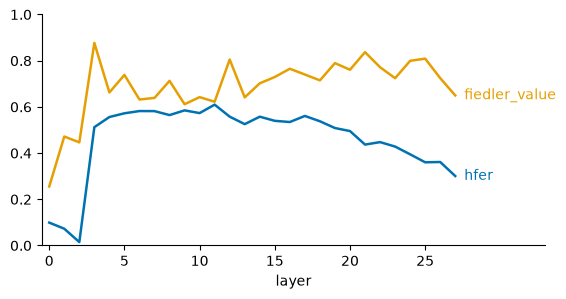

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6.5, 3))
for name, colour in (("fiedler_value", "#E69F00"), ("hfer", "#0072B2")):
    ax.plot(table.index, table[name], color=colour, lw=1.8)
    ax.text(table.index[-1] + 0.6, table[name].iloc[-1], name, color=colour, va="center")
ax.set_xlabel("layer")
ax.set_ylim(0, 1)
ax.set_xlim(-0.5, table.index[-1] + 6)
ax.set_xticks(range(0, len(table), 5))
ax.spines[["top", "right"]].set_visible(False)
plt.show()